#### Hyperparameters

In [10]:
from ADPIMH import BAIM, IndMH, pCN, adp_only
from ADPestimators import First_Est, Odd_ratio, Second_Est, EXP_Est
from Distributions import Stochastic_Volatility, Bayesian_Logistic_Regression, GP_Regression
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


distribution1 = "multivariate_normal"
distribution2 = "student_t"
distribution3 = "bayesian_logistic_regression"
distribution4 = "GP_Regression"
dataset = "pendulum" #'caravan', 'pima',  'ripley', 'australian','german', 'heart'

proposal = distribution1  # Target and Proposal distribution
target = distribution4
d=10
df = 10

#### Set $\mu$ and $L$

In [11]:
from sklearn.linear_model import LogisticRegression

if target == "bayesian_logistic_regression":
    est = Bayesian_Logistic_Regression()
    est.load_data(dataset)
    d = np.shape(est.inputs)[1] + 1
    # Fit = LogisticRegression()
    # para = Fit.fit(est.inputs, est.outputs)

    # true_mean = np.append(para.coef_,para.intercept_)
    
    col_ones = np.ones((est.inputs.shape[0], 1), dtype=jnp.float64)
    est.inputs = jnp.concatenate((est.inputs, col_ones), axis=1)
    print(est.inputs.shape)

    # xs = est.inputs @ true_mean.T
    # xxs = np.exp(xs) / (1 + np.exp(xs)) ** 2
    # xxs1 = 1 / (1 + np.exp(xs)) **2
    # W = np.diag(xxs)
    # Wh = np.diag(xxs1)
    # c = np.linalg.inv(est.inputs.T @ W @ est.inputs)
    # c1 = est.inputs.T @ Wh @ est.inputs
    # cov = c @ c1 @ c
    # true_L = np.linalg.cholesky(cov)

    mu1 = None
    L1 = None
    # print(true_mean)
    L2 = np.eye(d)
    # mu2 = true_mean
    mu2 = np.zeros(d)
elif target == "GP_Regression":
    est = GP_Regression()
    est.load_data(dataset)
    d = 3
    mu1 = None
    L1 = None
    mu2 = np.ones(d)
    L2 = np.eye(d)
else:
    est = None
    mu1 = np.zeros(d)    # mu1 = [0,0,...,0], L1 = diag(1) is the target distribution
    L1 = np.eye(d)      # mu2 = [1,1,...,1], L2 = L1*1.1 is the proposal distribution
    mu2 = np.ones(d)
    L2 = np.zeros((d, d))
    for i in range(d):
        for j in range(d):
            if i >= j:
                L2[i, j] = 1
    L2 = np.eye(d)

5000/5000 batches adapted !

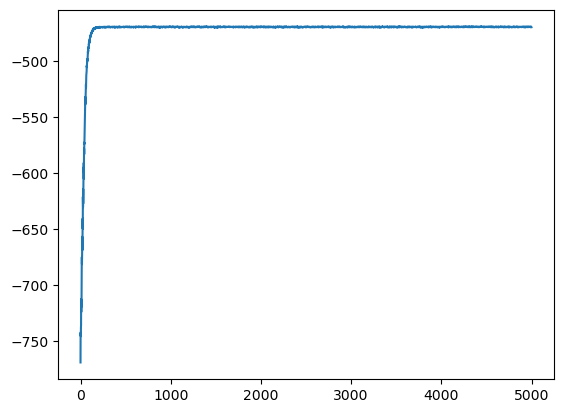

In [12]:
lr_burnin = 0.01                    # learning rate
Itr_burnin = 500000                  # Number of iterations of MCMC
batch_size_burnin = 100
Myadp = adp_only(target, proposal,Itr_burnin, batch_size_burnin,d,lr_burnin,est,df)
Myadp.set_distribution_parameters(mu1,L1,mu2,L2)
resul1 = Myadp.adp(True)
plt.plot(resul1)
plt.show()
mu2 = Myadp.p_mean
L2 = Myadp.p_L

In [7]:
from tqdm import tqdm

results = []
epoch = 50

Sample_N = 5001
Itr = Sample_N+100
lr=0
for i in tqdm(range(epoch)):
    MyIMH = IndMH(target, proposal, Itr,  d, lr, est, df, i + 10)
    MyIMH.set_distribution_parameters(mu1, L1, mu2, L2)
    resul = MyIMH.IMH()
    results.append(resul)



100%|██████████| 50/50 [03:47<00:00,  4.55s/it]


In [22]:
Ans = np.zeros((5,epoch,d))
accm = np.zeros((epoch,1))
coef_1 = np.zeros((epoch, d))
coef_2 = np.zeros((epoch, d))
coef_static = np.zeros((epoch, d))

Ans2 = np.zeros((5,epoch))
acoef_1 = np.zeros(epoch)
acoef_2 = np.zeros(epoch)
acoef_static = np.zeros(epoch)

for i in range(epoch):
    A = results[i][0]
    B = results[i][1]
    C = results[i][2]
    D = results[i][3]
    E = results[i][4]
    accm[i] = np.mean(E)
    for j in range(d):
        Esti = EXP_Est(Sample_N, 1,j)
        Esti.sample_loader(A,B,C,D)
        Ans[0,i,j] = Esti.IM()
        Ans[1,i,j] = Esti.IMCV()
        Ans[2,i,j],coef_1[i,j],coef_2[i,j] = Esti.IMCV_coef()
        Ans[3,i,j] = Esti.IMCV_poisson()
        Ans[4,i,j],coef_static[i,j] = Esti.IMCV_static()
    Esti2 = Odd_ratio(Sample_N, 1)
    Esti2.pre_proc(est.inputs)
    Esti2.sample_loader(A,B,C,D)
    Ans2[0,i] = Esti2.IM()
    Ans2[1,i] = Esti2.IMCV()
    Ans2[2,i],acoef_1[i],acoef_2[i] = Esti2.IMCV_coef()
    Ans2[3,i] = Esti2.IMCV_poisson()
    Ans2[4,i],acoef_static[i] = Esti2.IMCV_static()

accm_mean = accm.mean()
coef1 = coef_1.mean()
coef2 = coef_2.mean()
coef_static = coef_static.mean()

acoef1 = acoef_1.mean()
acoef2 = acoef_2.mean()
acoef_static = acoef_static.mean()

print("acc: ",accm_mean)
print("imcv_coef: ", coef1, coef2)
print("cim_coef: ", coef_static)
VRFs = np.zeros((5,d))
for i in range(5):
    VRFs[i] = Ans[0].var(axis = 0) / Ans[i].var(axis = 0)
    min_vrf = min(VRFs[i])
    max_vrf = max(VRFs[i])
    if 1 <= i < 6:
        print(f"& {min_vrf:.1f}-{max_vrf:.1f} ", end="")
    elif i >= 6:
        print(f"& {min_vrf:.1f}-{max_vrf:.1f} \\\\ \\hline")
    if 1 <= i < 6:
        print(f"& {VRFs[i][0]:.1f},{VRFs[i][1]:.1f},{VRFs[i][2]:.1f} ", end="")
    elif i >= 6:
        print(f"& {VRFs[i][0]:.1f},{VRFs[i][1]:.1f},{VRFs[i][2]:.1f} \\\\ \\hline")

print("imcv_coef: ",acoef1,acoef2)
print("cim_coef: ",acoef_static)
VRFs = np.zeros(5)
for i in range(5):
    VRFs[i] = Ans2[0].var() / Ans2[i].var()
print(VRFs)

AttributeError: 'GP_Regression' object has no attribute 'inputs'

In [13]:
from tqdm import tqdm

results = []
epoch = 20

lr = 0.00001
batch_size = 51
Sample_N = batch_size * 100
Itr = Sample_N+batch_size*20

for i in tqdm(range(epoch)):
    MyIMH = BAIM(target, proposal, Itr, batch_size, d, lr, est, df, i + 10)
    MyIMH.set_distribution_parameters(mu1, L1, mu2, L2)
    resul = MyIMH.adpIMH()
    results.append(resul)



100%|██████████| 20/20 [05:43<00:00, 17.20s/it]


In [14]:
Ans = np.zeros((5,epoch,d))
accm = np.zeros((epoch,1))
coef_1 = np.zeros((epoch, d))
coef_2 = np.zeros((epoch, d))
coef_01=np.zeros((epoch, d))
coef_02=np.zeros((epoch, d))
coef_static = np.zeros((epoch, d))
for i in range(epoch):
    A = results[i][0]
    B = results[i][1]
    C = results[i][2]
    D = results[i][3]
    E = results[i][6]
    accm[i] = np.mean(E)
    for j in range(d):
        Esti = EXP_Est(Sample_N, batch_size, j)
        Esti.sample_loader(A,B,C,D)
        Ans[0,i,j] = Esti.IM()
        Ans[1,i,j],coef_1[i,j],coef_2[i,j] = Esti.Batch_coef()
        Ans[2,i,j] = Esti.BatchIMCV()
        Ans[3,i,j] = Esti.BatchIMCV_poisson()
        Ans[4,i,j],coef_static[i,j] = Esti.BatchIMCV_static()
accm_mean = accm.mean()
coef1 = coef_1.mean()
coef2 = coef_2.mean()
coef_static = coef_static.mean()

print(accm_mean)
print(coef1)
print(coef2)
print(coef_static)
VRFs = np.zeros((5,d))
for i in range(5):
    VRFs[i] = Ans[0].var(axis = 0) / Ans[i].var(axis = 0)
    print(VRFs[i])

0.8745588235294118
1.0547997866357528
0.8978700912905311
0.89954837450201
[1. 1. 1.]
[2.67263289 4.44698567 7.5551142 ]
[2.90438675 3.1390105  7.22163904]
[1.10663103 1.30855253 1.48120509]
[1.94964693 1.86236899 2.9930179 ]


In [ ]:
# with open('resultheart.txt', 'w') as f:
#     f.write(str(accm_mean))
#     f.write('\n')
#     f.write(str(VRF1))
#     f.write('\n')
#     f.write(str(VRF2))
# f.close()

In [ ]:
strs = ['5', '10', '15','20','25','30','35','50','75','100']
IMCVS = []
IMCVS2 = []
accs = []
for i in strs:
    f = open('N'+i+'.txt', 'r')
    a = f.readline()
    b = f.readline()
    c = f.readline()
    accs.append(a[0:4])
    b = b[1:-2]
    b = np.fromstring(b, dtype=float, sep=' ')
    IMCVS.append(b)
    c = c[1:-2]
    c = np.fromstring(c, dtype=float, sep=' ')
    IMCVS2.append(c)

strs2 = ['5', '10', '15','20']
IMCVS3 = []
IMCVS4 = []
accs2 = []
for i in strs2:
    f = open('resultN'+i+'_2.txt', 'r')
    a = f.readline()
    b = f.readline()
    c = f.readline()
    accs2.append(a[0:4])
    b = b[1:-2]
    b = np.fromstring(b, dtype=float, sep=' ')
    IMCVS3.append(b)
    c = c[1:-2]
    c = np.fromstring(c, dtype=float, sep=' ')
    IMCVS4.append(c)

fig, axs = plt.subplots(figsize=(12, 6))
axs.set_xlim(0.7, 1)
axs.set_ylim(0, 200)
axs.tick_params(rotation=45)
axs.set_title('Variance Reduction Factor for different dimensional Normal problem')
axs.set_ylabel('Variance Reduction Factor')
axs.set_xlabel('Acceptance Rate')
pos = [0.975,0.96,0.945,0.93,0.91,0.895,0.88,0.83,0.78, 0.74]
pos2 = [0.98,0.965,0.95,0.935]
for i in range(len(strs)):
    axs.text(pos[i], 115 - np.log(i+1) / np.log(1.3) * 10, strs[i] + 'd', fontsize=12, horizontalalignment='center', verticalalignment='center',  c='black')
bp1 = axs.boxplot(IMCVS2, widths=0.005, positions= pos,patch_artist=True)
bp2 = axs.boxplot(IMCVS4, widths=0.005, positions= pos2,patch_artist=True)
axs.set_xticks(pos, accs)
[bp1['boxes'][i].set(facecolor='lightblue', alpha=0.7) for i in range(len(strs))]
[bp2['boxes'][i].set(facecolor='lightgreen', alpha=0.7) for i in range(len(strs2))]

axs.legend([bp1["boxes"][0], bp2["boxes"][0]], ['b=50,n=20', 'b=500,n=200'], loc='upper left')
plt.show()
plt.scatter([5,10,15,20,25,30,35,50,75,100],[0.97,0.96,0.95,0.93,0.91,0.89,0.88,0.83,0.76,0.67], marker='x',s=60, c = 'r')
plt.title('Acceptance Rate for different dimensional Normal problem')
plt.ylabel('Acceptance Rate')
plt.xlabel('Dimension')
plt.show()

FileNotFoundError: [Errno 2] No such file or directory: 'N5.txt'

['0.93', '0.81']


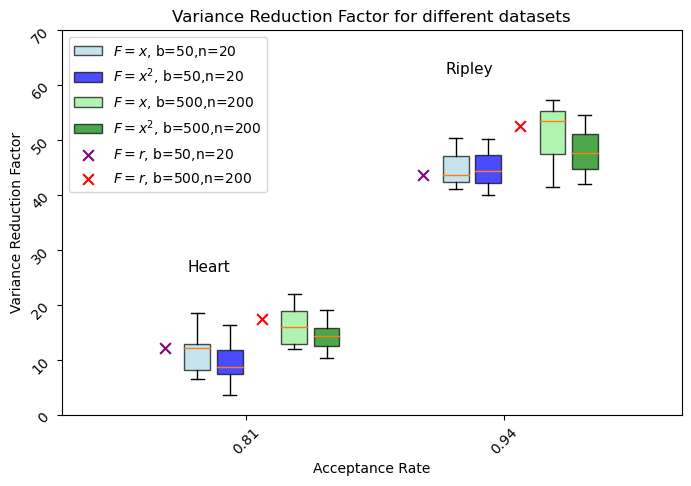

In [ ]:
strs = ['ripley', 'heart']
IMCVS = []
IMCVS2 = []
accs = []
for i in strs:
    f = open('result'+i+'.txt', 'r')
    a = f.readline()
    b = f.readline()
    c = f.readline()
    accs.append(a[0:4])
    b = b[1:-2]
    b = np.fromstring(b, dtype=float, sep=' ')
    IMCVS.append(b)
    c = c[1:-2]
    c = np.fromstring(c, dtype=float, sep=' ')
    IMCVS2.append(c)
print(str(accs))

IMCVL = []
IMCVL2 = []
strsL = ['ripley', 'heart']
for i in strsL:
    f = open(i+'L.txt', 'r')
    a = f.readline()
    b = f.readline()
    c = f.readline()
    b = b[1:-2]
    b = np.fromstring(b, dtype=float, sep=' ')
    IMCVL.append(b)
    c = c[1:-2]
    c = np.fromstring(c, dtype=float, sep=' ')
    IMCVL2.append(c)


fig, ax = plt.subplots(figsize=(8, 5))
ax.set_title('Variance Reduction Factor for different datasets')
ax.set_ylabel('Variance Reduction Factor')
ax.set_xlabel('Acceptance Rate')
ax.set_ylim(0, 70)
ax.tick_params(labelrotation=45)
ax.set_xlim(0.62, 1.1)
base1 = 0.9
base2 = 0.7
interval = 0.025
pos1 = [base1, base2]
pos2 = [base1 + interval, base2 + interval]
pos3 = [base1 + 2 * interval, base2 + 2 * interval]
pos4 = [base1 + 3 * interval, base2 + 3 * interval]
pos5 = [base1 + 4 * interval, base2 + 4 * interval]
pos6 = [base1 + 5 * interval, base2 + 5 * interval]
posm = [base1 + 2.5 * interval, base2 + 2.5 * interval]

bp1 = ax.boxplot(IMCVS,widths= interval - 0.005, positions = pos2, patch_artist=True)
bp2 = ax.boxplot(IMCVS2,widths= interval - 0.005, positions =  pos3, patch_artist=True)
bp3 = ax.boxplot(IMCVL,widths=interval - 0.005, positions = pos5, patch_artist=True)
bp4 = ax.boxplot(IMCVL2,widths=interval - 0.005, positions =  pos6, patch_artist=True)

p1 = ax.scatter(pos1,[43.6,12.2], marker='x',s=60, c = 'purple')
p2 = ax.scatter(pos4,[52.5,17.4], marker='x',s=60, c = 'red')

ax.set_xticks(posm,[0.94,0.81])
[bp1['boxes'][i].set(facecolor='lightblue', alpha=0.7) for i in range(2)]
[bp2['boxes'][i].set(facecolor='blue', alpha=0.7) for i in range(2)]
[bp3['boxes'][i].set(facecolor='lightgreen', alpha=0.7) for i in range(2)]
[bp4['boxes'][i].set(facecolor='green', alpha=0.7) for i in range(2)]
ax.text(base1 + 0.7*interval, 62, 'Ripley', fontsize=11)
ax.text(base2 + 0.7*interval, 26, 'Heart', fontsize=11)

ax.legend([bp1["boxes"][0], bp2["boxes"][0], bp3["boxes"][0], bp4["boxes"][0], p1, p2], 
          ['$F=x$, b=50,n=20', '$F=x^2$, b=50,n=20', '$F=x$, b=500,n=200', '$F=x^2$, b=500,n=200', '$F=r$, b=50,n=20', '$F=r$, b=500,n=200'], loc='upper left')
plt.show()